In [1]:
import simsopt.configs.zoo as zoo
import numpy as np
import matplotlib.pyplot as plt
coils, currents, ma = zoo.get_w7x_data()

/tmp/ipykernel_624/2244998250.py:4: DeprecationWarning: get_w7x_data is deprecated and will be removed in the next major release; please use get_data('w7x', coil_order=..., magnetic_axis_order=..., points_per_period=...) instead.
  coils, currents, ma = zoo.get_w7x_data()


In [2]:
curve = coils[0]
print(curve.order)

48


In [3]:
order=curve.order
curve_coeffs= curve.get_dofs()

In [4]:
# Below Labels Coeffiecients
for name, val in zip(curve.dof_names, curve.get_dofs()):
    print(f"{name:<20} | {val: .6f}")

CurveXYZFourier1:xc(0) |  5.825610
CurveXYZFourier1:xs(1) | -0.024254
CurveXYZFourier1:xc(1) |  0.908578
CurveXYZFourier1:xs(2) |  0.045181
CurveXYZFourier1:xc(2) |  0.201459
CurveXYZFourier1:xs(3) | -0.042815
CurveXYZFourier1:xc(3) | -0.136418
CurveXYZFourier1:xs(4) |  0.010303
CurveXYZFourier1:xc(4) |  0.039924
CurveXYZFourier1:xs(5) |  0.004071
CurveXYZFourier1:xc(5) |  0.008068
CurveXYZFourier1:xs(6) | -0.001976
CurveXYZFourier1:xc(6) | -0.004881
CurveXYZFourier1:xs(7) | -0.000707
CurveXYZFourier1:xc(7) |  0.003225
CurveXYZFourier1:xs(8) |  0.003491
CurveXYZFourier1:xc(8) | -0.003634
CurveXYZFourier1:xs(9) | -0.001602
CurveXYZFourier1:xc(9) |  0.000230
CurveXYZFourier1:xs(10) | -0.001754
CurveXYZFourier1:xc(10) |  0.000324
CurveXYZFourier1:xs(11) |  0.000377
CurveXYZFourier1:xc(11) |  0.000270
CurveXYZFourier1:xs(12) |  0.000826
CurveXYZFourier1:xc(12) | -0.000502
CurveXYZFourier1:xs(13) | -0.000924
CurveXYZFourier1:xc(13) |  0.001178
CurveXYZFourier1:xs(14) |  0.001025
CurveXYZFou

In [5]:
# Every array here has sine and coine coefficients 1-48 for their respective values, they do not have the 0th coefficient
# Also note that since we are given 49 coefficients for sine and cosine, the 49th will correspond to omega=pi harmonic, so we will have 96 samples
x_cos= curve_coeffs[2:order*2+1:2]
x_sin=curve_coeffs[1:order*2:2]
y_cos=curve_coeffs[order*2+3:order*4+3:2]
y_sin=curve_coeffs[order*2+2:order*4+2:2]
z_cos=curve_coeffs[order*4+4::2]
z_sin= curve_coeffs[order*4+3::2]
print(x_cos.size)

48


In [6]:
# We only have omega<pi here because fourier coeficients for frequncies where omega>pi have been combined with coefficients for omega<pi to get sine and cos coefficients
# Below the omega array does not include 0 because 0th cosine coefficient is added to array seperately
# We have 96 frequencies for omega. 0 is not included in omega vector because the 0th harmonic as added on its own.
# Omega array starts at 2pi/96, it end at pi (the 49th coefficients correspond to omega=pi)
# I have omega sampled 48 times because that is the number of sine and cosine coefficient (not including the 0 coefficient)

# *Before, when we were in the zoom, my code used theta for this vector instead of Omega, 
# I changed it from theta to omega because it makes more sense to look at this vector as the frequencies 
# and the counter in the loop below going through the samples of theta on the coil curve

# *Also earlier I had assumed that every coefficient not corresponding to the 0th vector would be doubled so I didn't think one of them would correspond to
# omega=pi, this is why they were not matching the simsopt coefficients and why simsopt had one less sample before
# omega= np.linspace(2*np.pi/(2*order+1),1*np.pi-(np.pi/(2*order+1)),order)
# This was my previous code. I had also made a similar mistake when taking the IDFT, 
# I appended the conjugate of each entry to the DFT vector instead of keeping the 49 entry unique.
omega= np.linspace(2*np.pi/(2*order),1*np.pi,order)
print(omega.size ) # Checking to make sure omega has 48 values

48


In [7]:
# Below creates arrays for each coordinate of size they have 96 entries each for each sample every sample
y_sum =np.full((order*2,1),0.0)
x_sum = np.full((order*2,1),0.0)
z_sum =np.full((order*2,1),0.0)

In [9]:
counter=0 # We are interating through every sample
while(counter<order*2):
    sin_vals = np.sin(counter*omega) # Take sine and cos of omega array for each sample
    cos_vals= np.cos(counter*omega) # Take sine and cos of omega array for each sample
    #This part: np.dot(x_cos,cos_vals)+ np.dot(x_sin,sin_vals) dots sin/cos coeffs 1-48 with sinusoids of harmonics 1-48, 
    # The 0th coefficient is added to the rest of the harmonics for each sample
    x_sum[counter] = curve_coeffs[0]  +  np.dot(x_cos,cos_vals)+ np.dot(x_sin,sin_vals) 
    y_sum[counter]  =curve_coeffs[order*2+1]  + np.dot(y_cos,cos_vals)+ np.dot(y_sin,sin_vals)
    z_sum[counter]  =curve_coeffs[order*4+2] + np.dot(z_cos,cos_vals)+  np.dot(z_sin,sin_vals)
    counter=counter+1

96


Text(0.5, 0, 'Z Axis')

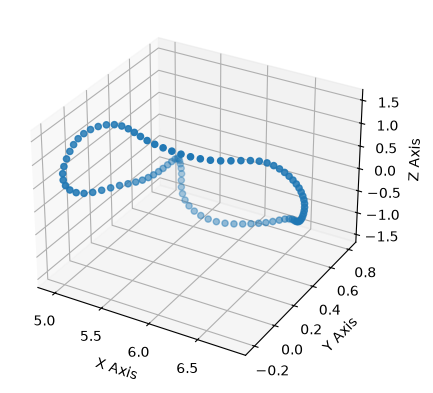

In [10]:
print(x_sum.size)
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(x_sum, y_sum, z_sum)
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')

Checking if coordinates from Simsopt and sum are same:

In [11]:
xyz_coords = curve.gamma()
print(xyz_coords[:,0].size)#Prints size of one of the coordinate vectors
for item1, item2 in zip(x_sum, xyz_coords[:,0]):
    print(f"{item1}\t{item2}")

96
[6.84262071]	6.84262071099998
[6.83949857]	6.839498568000024
[6.8315061]	6.831506098000009
[6.81861741]	6.818617411999978
[6.80095608]	6.800956077000032
[6.77878805]	6.778788050999988
[6.75211334]	6.752113338999976
[6.72114966]	6.721149657000012
[6.68597997]	6.685979972000013
[6.64695321]	6.646953209999989
[6.60431769]	6.6043176900000145
[6.5587089]	6.5587088960000095
[6.51159669]	6.511596693999965
[6.4641438]	6.464143797999995
[6.41535226]	6.41535225900001
[6.36361098]	6.363610984000006
[6.3076537]	6.307653700000021
[6.24592463]	6.245924626999993
[6.17794186]	6.177941863999993
[6.10468924]	6.104689237999974
[6.02664572]	6.026645718000006
[5.9448075]	5.944807497999971
[5.86007427]	5.860074265000048
[5.77324862]	5.773248621999984
[5.68550034]	5.685500340000005
[5.59823397]	5.5982339720000045
[5.51154661]	5.511546607000004
[5.42525937]	5.4252593650000005
[5.33930576]	5.339305756000003
[5.2550362]	5.255036195999972
[5.17563873]	5.175638729
[5.10445968]	5.104459682999996
[5.04454176]	5.

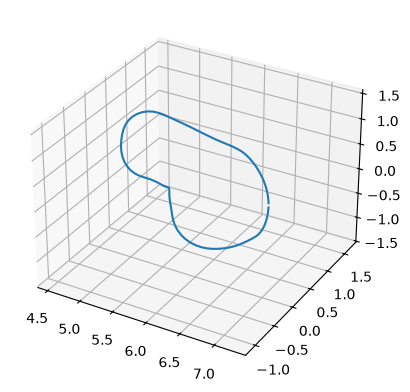

<Axes3D: >

In [12]:
# Below plots using simsopt
curve.plot(engine="matplotlib")

Taking Inverse DFT (Same thing different method):

In [38]:
# Creating Coefficient arrays and inserting 0th sine coefficient
x_cos2= curve_coeffs[0:order*2+1:2]
x_sin2=curve_coeffs[1:order*2:2]
y_cos2=curve_coeffs[order*2+1:order*4+3:2]
y_sin2=curve_coeffs[order*2+2:order*4+2:2]
z_cos2=curve_coeffs[order*4+2::2]
z_sin2= curve_coeffs[order*4+3::2]

x_sin2 = np.insert(x_sin2, 0, 0)
y_sin2 = np.insert(y_sin2, 0, 0)
z_sin2 = np.insert(z_sin2, 0, 0)

In [39]:
# Appending reversed array (except for first and last entry which correspond to omega=0 and omgea=pi) to array
# negating sine entries for conjugate circular symmetry
x_cos2 = np.append(x_cos2, x_cos2[1:48][::-1])
x_sin2 = np.append(x_sin2, -1*x_sin2[1:48][::-1])
y_cos2 = np.append(y_cos2, y_cos2[1:48][::-1])
y_sin2 = np.append(y_sin2, -1*y_sin2[1:48][::-1])
z_cos2 = np.append(z_cos2, z_cos2[1:48][::-1])
z_sin2 = np.append(z_sin2, -1*z_sin2[1:48][::-1])

#*Before I had appended the conjugate of the 48th coefficient as well because I had not realized it corresponded to omega=pi
# That is why time method gave me the same result as manually doing the summing (which I was doing with an additional harmonic before)
# Now it is corrected and gives same result as simsopt
#x_cos2 = np.append(x_cos2, x_cos2[1:][::-1])


In [40]:
# Converting Sin and Cosine coefficients to fourier coeffitients
# Multipy whole array by 97 to get DFT from coefficient vector. 
# harmonics by 2 becuase sine and cosine coefficients were added together for negative and positive frequncies.
arr = np.full(96, 96/2, dtype=float)
#0th harmonic and 48th harmonic were not doubled
arr[0] = 96.0
arr[48] = 96.0

# Below creates DFT vectors
x_fft= (x_cos2-1j*x_sin2)*arr
y_fft=(y_cos2-1j*y_sin2)*arr
z_fft=(z_cos2-1j*z_sin2 )*arr

In [36]:
# Take inverse fourier transform
x_ift=np.fft.ifft(x_fft)
y_ift=np.fft.ifft(y_fft )
z_ift=np.fft.ifft(z_fft )

In [37]:
# We get same result from IDFT and doing the summing manually
for item1, item2 in zip(x_sum, x_ift):
    print(f"{item1}\t{item2}")

[6.84262071]	(6.842620710999977+1.5997750338676512e-15j)
[6.83949857]	(6.839498568000025-1.622615559634679e-15j)
[6.8315061]	(6.8315060980000055+1.6064248071922288e-15j)
[6.81861741]	(6.818617411999977-1.5925470193844143e-15j)
[6.80095608]	(6.800956077000028+1.609026892406194e-15j)
[6.77878805]	(6.778788050999987-1.5535247761930403e-15j)
[6.75211334]	(6.7521133389999815+1.5999195941573158e-15j)
[6.72114966]	(6.721149657000012-1.5720194582520222e-15j)
[6.68597997]	(6.685979972000011+1.5997750338676512e-15j)
[6.64695321]	(6.646953209999992-1.6463234471396953e-15j)
[6.60431769]	(6.60431769000001+1.5908122959084375e-15j)
[6.5587089]	(6.558708896000013-1.5815604373698947e-15j)
[6.51159669]	(6.511596693999966+1.609026892406194e-15j)
[6.4641438]	(6.4641437979999985-1.562758564695375e-15j)
[6.41535226]	(6.415352259000007+1.5996304735779864e-15j)
[6.36361098]	(6.3636109840000055-1.636782468021823e-15j)
[6.3076537]	(6.307653700000023+1.5997750338676512e-15j)
[6.24592463]	(6.24592462699999-1.6318